In [471]:
import neuron
from neuron import h
import matplotlib.pyplot as plt
from neuron.units import ms, mV
import numpy as np
pth_mod = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod'
figpth = '/Users/katharinaduecker/Documents/projects_brown/hnn_dev/figures/newl3_iascone/'
import os
#os.mkdir(figpth)
from cell_builder_utils import l2_params, _get_dends, _get_pyr_soma, Cell
from iascone_mechs_utils import Mechs, get_iascone_params, Ih_condu_apical, distribute_gbar
from plot_utils import fig_conductances, fig_compartments
from functools import partial

from hnn_core.viz import plot_cell_morphology

In [472]:
#iascone_model_params = get_iascone_params() # original params

In [ ]:
iascone_model_params = {'soma': {'NaTs2_t_l23': 20_400e-4*0.5,
                                'SKv3_1': 6_930e-4*0.2,
                                'Nap_Et2': 1e-4,
                                'Ca_HVA': 9.92e-04,
                                'Ca_LVAst': 34.3e-4*1.5,
                                'SK_E2': 0.099433*0.001,
                                'pas': 1.0 / 12000.0,
                                'Ih': 0.000080*5,
                                'Im': 8e-3},
                        'dend': {'NaTa_t_l23': 0.008009,
                                'SKv3_1': 0.000513*15,
                                'Ca_HVA': 0.000374e-2*100,
                                'Ca_LVAst': 0.000778e-2*100,
                                'pas': 1.0 / 12000.0,
                                'Ih': {'gbar': 0.000080*10, 'offset': -0.869600, 'slope':4, 'factor_exp':1/110},
                                'Im': 8e-3},
                        'e_pas': -85}

In [474]:
# get paramaters
section_params, end_pts, cell_tree = l2_params()

# build sections
section_names = list(end_pts.keys())

sections = _get_dends(section_params, 'L2Pyr', section_names, end_pts)
sections['soma'] = _get_pyr_soma(section_params, 'L2Pyr', end_pts['soma'])

mech_class = Mechs(pth_mod)

l2pyr= Cell(sections, cell_tree, cell_type = 'L2_pyramidal', gid=0)
l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)


Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod.  Aborting.


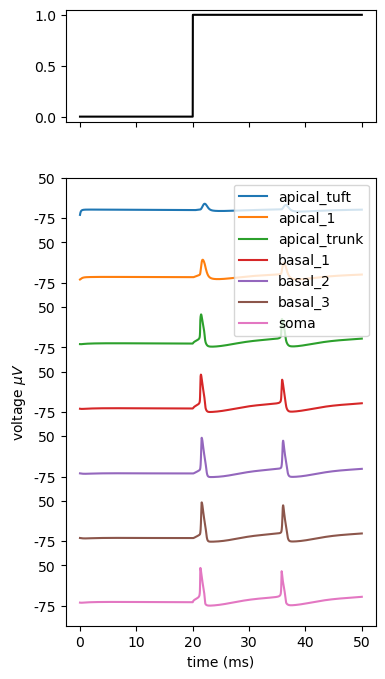

In [475]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

num_pulse = 1
stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 20+(10*i)
    stim[i].dur = 1000
    stim[i].amp = 1
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)

fig = fig_voltage(l2pyr, clamp_current, l_stim=50)
fig.savefig(figpth+'continuous_clamp.png')

<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:18: SyntaxWarning: invalid escape sequence '\m'
<>:16: SyntaxWarning: invalid escape sequence '\m'
<>:18: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_6562/4076689579.py:16: SyntaxWarning: invalid escape sequence '\m'
  ax[0].set_xlabel('distance to soma ($\mu m$)')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_6562/4076689579.py:18: SyntaxWarning: invalid escape sequence '\m'
  ax[1].set_xlabel('distance to soma ($\mu m$)')


Text(0.5, 0, 'distance to soma ($\\mu m$)')

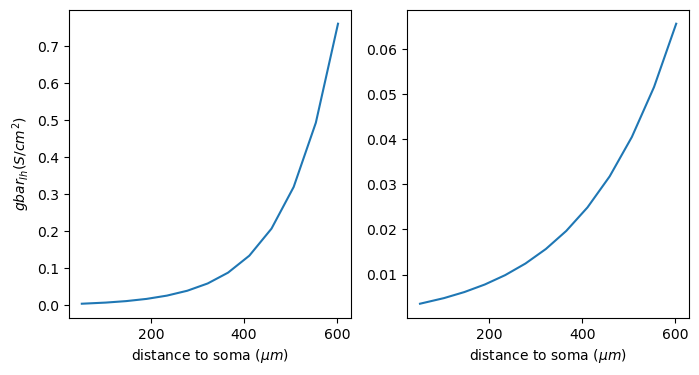

In [476]:
distance_apical = []
gbar_Ih_apical = []
Ih_fun = []
apical_sections = ['apical_trunk', 'apical_1','apical_tuft']

h.distance(sec = l2pyr._nrn_sections['soma'])
for section in apical_sections:
    for seg in l2pyr._nrn_sections[section]:
        distance_apical.append(h.distance(seg.x, sec=seg.sec))
        gbar_Ih_apical.append(seg.gbar_Ih)
        Ih_fun.append(Ih_condu_apical(iascone_model_params['dend']['Ih']['gbar'],-0.869600, 2.087+2, 1/200,h.distance(seg.x, sec=seg.sec)))

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(distance_apical, gbar_Ih_apical)
ax[0].set_ylabel('$gbar_{Ih} (S/cm^2)$')
ax[0].set_xlabel('distance to soma ($\mu m$)')
ax[1].plot(distance_apical, Ih_fun)
ax[1].set_xlabel('distance to soma ($\mu m$)')


In [477]:
def fig_voltage(model, clamp_current, l_stim=100):
    
    section_names = ['apical_tuft', 'apical_1', 'apical_trunk', 'basal_1', 'basal_2', 'basal_3', 'soma']

    voltg = [None]*len(section_names)
    for i, section in enumerate(section_names):
        voltg[i] = h.Vector().record(model._nrn_sections[section](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    h.celsius = 34
    h.finitialize(-65 * mV)
    h.continuerun(l_stim * ms)

    fig, ax = plt.subplots(2,1, figsize=(4,8), height_ratios=[0.25, 1], sharex=True)

    for c in clamp_current:
        ax[0].plot(t,c, color='k')

    yticks_v = []
    yticklabels_v = []

    cv = 0
    for i,section in enumerate(section_names):
        
        ax[1].plot(t,voltg[i] + cv)

        yticks_v.append(-75+cv)
        yticks_v.append(50+cv)

        yticklabels_v.append(str(np.round(-75)))
        yticklabels_v.append(str(np.round(50)))

        cv -= 200

    ax[1].set_yticks(yticks_v)
    ax[1].set_yticklabels(yticklabels_v)
    ax[1].set_ylabel('voltage $\mu V$')
    ax[1].set_xlabel('time (ms)')
    ax[1].legend(section_names)

    return fig

<>:38: SyntaxWarning: invalid escape sequence '\m'
<>:38: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_6562/2091062747.py:38: SyntaxWarning: invalid escape sequence '\m'
  ax[1].set_ylabel('voltage $\mu V$')


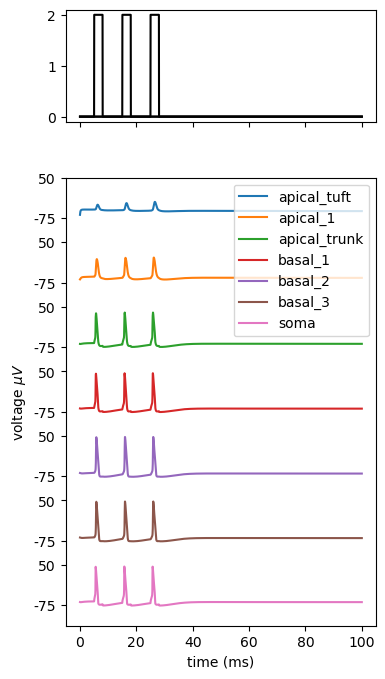

In [478]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

num_pulse = 3
stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 5+(10*i)
    stim[i].dur = 3
    stim[i].amp = 2.
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)


fig = fig_voltage(l2pyr, clamp_current)
fig.savefig(figpth+'spiking.png')

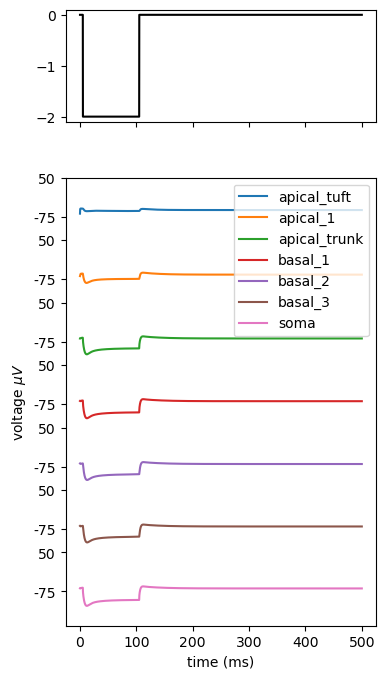

In [479]:
l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

l2pyr.build()
l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

num_pulse = 1
stim = [None]*num_pulse
clamp_current = [None]*num_pulse
for i in range(num_pulse):
    stim[i] = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim[i].delay = 5+(10*i)
    stim[i].dur = 100
    stim[i].amp = -2
    clamp_current[i] = h.Vector().record(stim[i]._ref_i)

fig = fig_voltage(l2pyr, clamp_current, l_stim=500)
fig.savefig(figpth+'sag.png')

<>:39: SyntaxWarning: invalid escape sequence '\m'
<>:39: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_6562/2535374077.py:39: SyntaxWarning: invalid escape sequence '\m'
  ax[1].set_ylabel('membrane potential $\mu V$')


lowest ampl to induce spike: 0.5


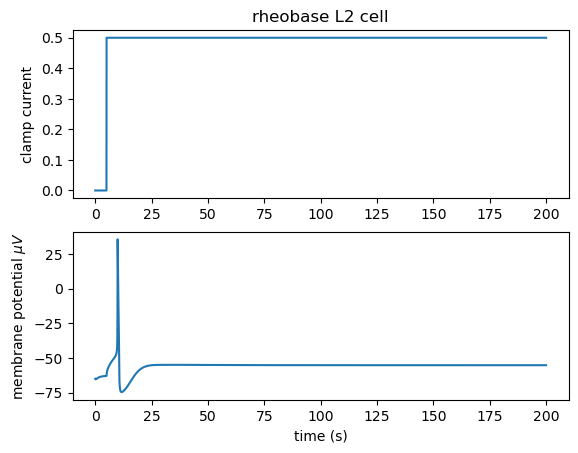

In [480]:
# rheobase
from scipy.signal import find_peaks

ampl = np.arange(0.5,1.5,0.05)

for a in ampl:
    l2pyr= Cell(sections, cell_tree, cell_type='L5_pyramidal', gid=0)
    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

    # critical freq
    num_pulse = 3
    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 5
    stim.dur = 1000
    stim.amp = a
    clamp_current = h.Vector().record(stim._ref_i)

    v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)


    h.celsius = 37
    h.finitialize(-65 * mV)
    h.continuerun(200 * ms)

    pk = find_peaks(v, height=0)
    if np.any(pk[0]) == True:
        print(f'lowest ampl to induce spike: {a}')
        break

fig, ax = plt.subplots(2,1)

ax[0].plot(t,clamp_current)
ax[0].set_ylabel('clamp current')
ax[1].plot(t,v)
ax[1].set_xlabel('time (s)')
ax[1].set_ylabel('membrane potential $\mu V$')
ax[0].set_title('rheobase L2 cell')

fig.savefig(figpth+'rheobase.png')


# add basal dendrites

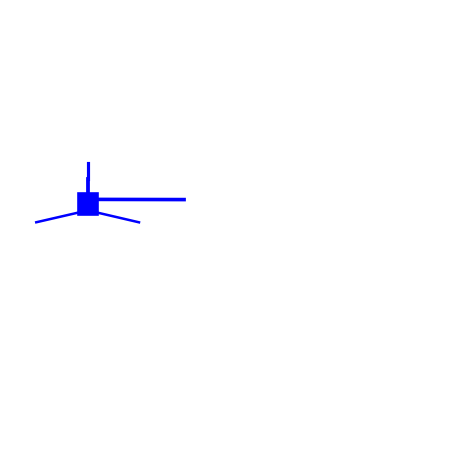

In [481]:
ax = plt.figure().add_subplot(projection='3d')
plot_cell_morphology(l2pyr, ax=ax, show=False)
ax.view_init(0,80)


HNN cell_default: proximal drive is basal_2, basal_3 and apical_oblique https://github.com/jonescompneurolab/hnn-core/blob/master/hnn_core/cells_default.py#L115

In [482]:
def epsp_sim(sections, cell_tree, epsp_strength = 1):

    # check EPSP effect
    l2pyr= Cell(sections, cell_tree, cell_type='L2_pyramdial', gid=0)

    l2pyr.build()
    l2pyr = mech_class.add_mechs(l2pyr, iascone_model_params)

    syn_inp = h.epsp(l2pyr._nrn_sections['basal_2'](0.9))
    syn_inp.onset = 5
    syn_inp.imax = epsp_strength

    h.distance(sec = l2pyr._nrn_sections['soma'])
    segments = [seg.x for seg in l2pyr._nrn_sections['basal_2']]

    voltg_basal = [None]*len(segments)
    for i, seg in enumerate(l2pyr._nrn_sections['basal_2']):
        voltg_basal[i] = h.Vector().record(seg._ref_v)

    voltg_apical = [None]*len(section_names)
    for i, section in enumerate(section_names):
        voltg_apical[i] = h.Vector().record(l2pyr._nrn_sections[section](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    l_stim = 100
    h.celsius = 34
    h.finitialize(-65 * mV)
    h.continuerun(l_stim * ms)

    return segments, voltg_basal, voltg_apical, t

<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:18: SyntaxWarning: invalid escape sequence '\m'
<>:12: SyntaxWarning: invalid escape sequence '\m'
<>:18: SyntaxWarning: invalid escape sequence '\m'
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_6562/857241758.py:12: SyntaxWarning: invalid escape sequence '\m'
  ax[0, a].set_ylabel('voltage $\mu V$')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_6562/857241758.py:18: SyntaxWarning: invalid escape sequence '\m'
  ax[1, a].set_ylabel('voltage $\mu V$')


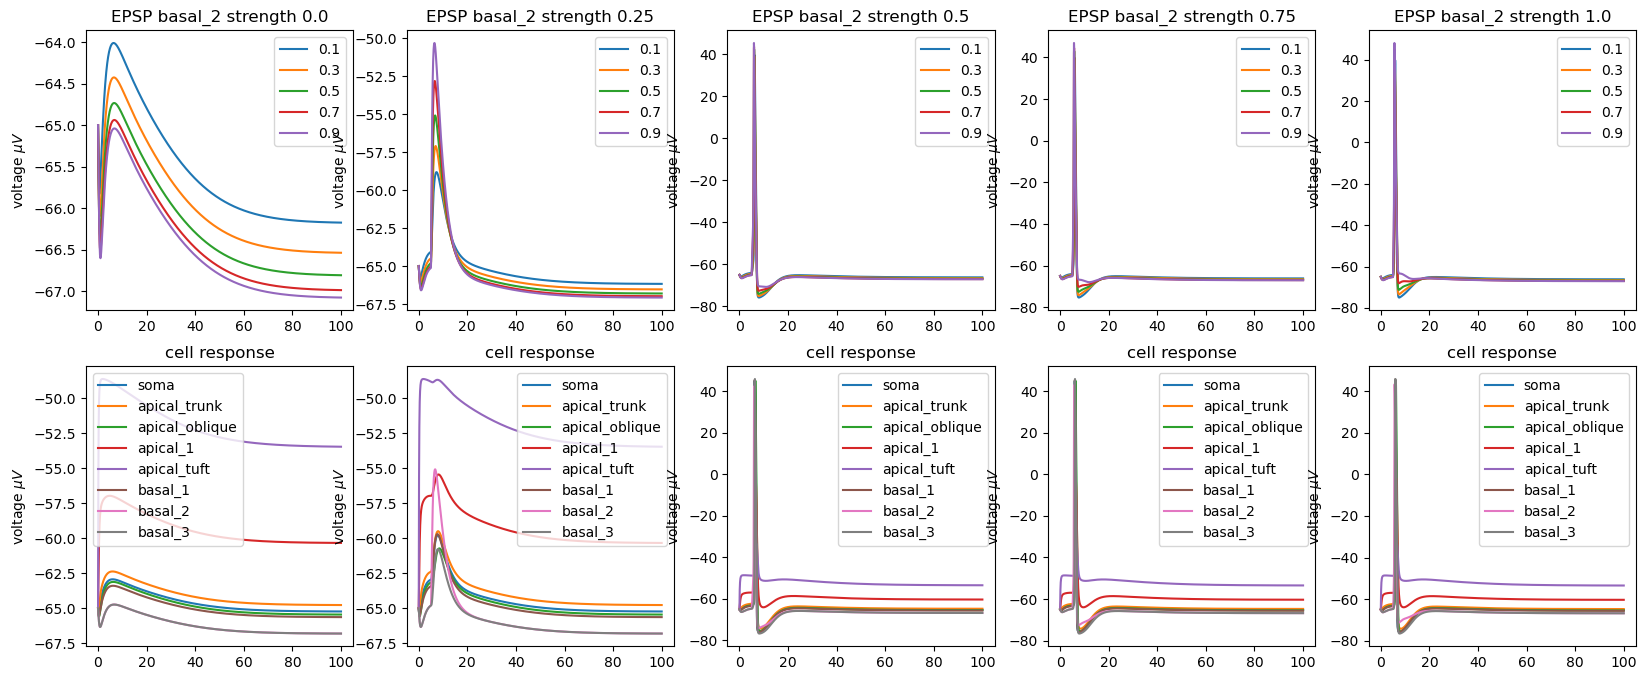

In [483]:
fig, ax = plt.subplots(2,5,figsize=(20,8))


for a, epsp_strength in enumerate(np.linspace(0,1,5)):
    segments, voltg_basal, voltg_apical, t = epsp_sim(sections, cell_tree, epsp_strength)

    for i,v in enumerate(voltg_basal):
        ax[0, a].plot(t,v, label=str(segments[i]))

    ax[0, a].legend()
    ax[0, a].set_title(f'EPSP basal_2 strength {str(np.round(epsp_strength,2))}')
    ax[0, a].set_ylabel('voltage $\mu V$')

    for i,v in enumerate(voltg_apical):
        ax[1, a].plot(t,v, label=section_names[i])
    ax[1, a].legend()
    ax[1, a].set_title('cell response')
    ax[1, a].set_ylabel('voltage $\mu V$')

fig.savefig(figpth+'basal_dendrites_epsps.png')

# F-I plots??


find objectives in /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/kalmbach_l5_human_electrophysio.xls